# 11b. Matériel, coût, débit : ce que paie réellement un token

[<< 11. Quantization](11_Quantization.ipynb) · [12. Test Time Scaling >>](12_Test_Time_Scaling.ipynb)

Les notebooks [10b](10b_Inference_Mechanics.ipynb) et [11](11_Quantization.ipynb) ont construit deux morceaux du même puzzle : le premier mesure les **mécaniques d'inférence** (KV-cache, préfill vs décodage, batching), le second les **formats de poids** (int4/int8, précision). Ce qui manque entre les deux — et c'est le sujet de ce carnet — c'est la **chaîne complète** :

> format numérique → VRAM occupée → bande passante consommée → débit observé → coût par million de tokens.

Chaque maillon est **mesuré sur une carte réelle de la flotte** : une RTX 4060 Laptop GPU (8 Go, Ada, compute capability 8.9), servie par Ollama avec `qwen2.5:7b-instruct-q4_K_M` — le même couple modèle/format que le [22c](22c_DSPy_Prompt_Compile.ipynb). Le toit bande passante/calcul (*roofline*) n'est pas un diagramme de manuel recopié : il est construit depuis les débits mesurés de la carte, puis **fermé** — le débit de décodage prédit par le toit est confronté au débit réellement observé, et l'écart est lu, pas caché.

**Classification des nombres.** Chaque grandeur du carnet porte son étiquette : **Mesuré** (relevé par le code sur cette machine, ce jour) ou **Cité** (donnée constructeur ou hypothèse déclarée, jamais présentée comme une mesure).


## 1. La carte de référence — ce qui se mesure, ce qui se cite

Le carnet interroge la carte par trois instruments distincts : `torch.cuda` (bande passante, VRAM par format), l'API d'Ollama (débits préfill/décodage), et `nvidia-smi` (horloge mémoire, puissance consommée). Un seul chiffre reste une donnée constructeur : la **largeur du bus mémoire** (128 bits pour cette famille), non exposée par les APIs — tout le reste se dérive de mesures locales.

L'horloge mémoire rendue par `nvidia-smi` est la fréquence *effective* GDDR6 : le débit théorique s'en dérive arithmétiquement (débit = fréquence données × largeur de bus). C'est la convention d'étiquetage de tout le carnet : **dérivé d'une mesure** quand l'arithmétique part d'un relevé local, **Cité** quand elle part d'une page constructeur.


In [1]:
# Parameters
OLLAMA_URL = "http://127.0.0.1:11434"   # endpoint local (API compatible OpenAI aussi utilisable)
MODEL_NAME = "qwen2.5:7b-instruct-q4_K_M"
PRIX_KWH_EUR = 0.25                     # hypothèse déclarée : prix de l'électricité (Cité, à adapter)
COUT_CARTE_EUR = 1000.0                 # hypothèse déclarée : prix d'achat de la carte
AMORTISSEMENT_ANS = 3.0                 # hypothèse déclarée : durée d'amortissement
UTILISATION_FRACTION = 0.20             # hypothèse déclarée : part du temps où la carte infère


In [2]:
import json
import math
import subprocess
import threading
import time

import matplotlib

try:
    get_ipython().run_line_magic("matplotlib", "inline")  # figures capturées en outputs
except Exception:
    pass
import matplotlib.pyplot as plt
import numpy as np
import requests
import torch

print("torch", torch.__version__, "| CUDA dispo :", torch.cuda.is_available())
print("carte :", torch.cuda.get_device_name(0))
print("compute capability :", torch.cuda.get_device_capability(0))


def nvidia_smi(*fields):
    out = subprocess.run(
        ["nvidia-smi", "--query-gpu=" + ",".join(fields), "--format=csv,noheader,nounits"],
        capture_output=True, text=True, timeout=10, encoding="utf-8", errors="replace",
    )
    return [float(x) for x in out.stdout.strip().split(",")]


mem_mib, mem_clock_mhz = nvidia_smi("memory.total", "clocks.max.memory")
print(f"VRAM totale : {mem_mib:.0f} MiB (Mesuré) | horloge mémoire max : {mem_clock_mhz:.0f} MHz (Mesuré)")

# Débit théorique GDDR6 : fréquence effective × 2 transferts/cycle/pin (DDR) × bus bits.
# Fréquence mesurée localement ; largeur de bus 128 bits = donnée constructeur (Cité).
BUS_BITS = 128  # Cité : spécification de la famille RTX 4060 Laptop
DEBIT_THEORIQUE_GB_S = mem_clock_mhz * 1e6 * 2 * BUS_BITS / 8 / 1e9
print(f"débit mémoire théorique dérivé : {DEBIT_THEORIQUE_GB_S:.1f} Go/s "
      f"(dérivé : horloge Mesurée x bus Cité)")


torch 2.14.0+cu126 | CUDA dispo : True
carte : NVIDIA GeForce RTX 4060 Laptop GPU
compute capability : (8, 9)
VRAM totale : 8188 MiB (Mesuré) | horloge mémoire max : 8001 MHz (Mesuré)
débit mémoire théorique dérivé : 256.0 Go/s (dérivé : horloge Mesurée x bus Cité)


L'horloge maximale rendue par `nvidia-smi` (8001 MHz en fréquence GDDR6) correspond à 16 Gt/s par broche ; sur un bus de 128 bits, cela borne le débit mémoire à **256 Go/s**. C'est le plafond **théorique** — la section suivante mesure ce que la carte rend effectivement, et l'écart entre les deux est déjà une information (contrôleur, ECC, fraîcheur des caches).


## 2. Le toit bande passante/calcul, construit depuis des mesures

Une opération sur GPU est bornée par le plus contraignant de deux plafonds : la **bande passante mémoire** (combien d'octets/s traversent le bus) et la **puissance de calcul** (combien d'opérations/s les unités calculent). Le *roofline* exprime cela par une seule variable, l'**intensité arithmétique** — le nombre d'opérations par octet lu :

$$\text{ops/s} = \min\left(\text{pics FLOP/s},\; \text{bande passante} \times \text{intensité arithmétique}\right)$$

Une multiplication matricielle large déplace chaque octet une fois pour beaucoup d'opérations (intensité élevée → bornée calcul). Relire *tous les poids* pour produire *un seul* token déplace des gigaoctets pour peu d'opérations (intensité faible → bornée mémoire). Avant de tracer le toit, il faut ses deux plafonds **mesurés** : la bande passante effective (stream triad sur GPU) et les FLOP/s effectifs (matmul en fp16 et fp32).


In [3]:
def mesure_bande_passante_gpu(n_elements=128 * 1024 * 1024, repetitions=8):
    """Stream triad d = a + 2.0*b sur GPU : 3 vecteurs fp32 traversent le bus a chaque passe."""
    a = torch.full((n_elements,), 1.5, device="cuda", dtype=torch.float32)
    b = torch.full((n_elements,), 2.0, device="cuda", dtype=torch.float32)
    d = torch.empty_like(a)
    for _ in range(3):  # échauffement
        torch.add(a, b, alpha=2.0, out=d)
    torch.cuda.synchronize()
    debut = torch.cuda.Event(enable_timing=True)
    fin = torch.cuda.Event(enable_timing=True)
    debut.record()
    for _ in range(repetitions):
        torch.add(a, b, alpha=2.0, out=d)
    fin.record()
    torch.cuda.synchronize()
    secondes = debut.elapsed_time(fin) / 1e3 / repetitions
    octets = 3 * n_elements * 4  # lecture a, lecture b, écriture d
    return octets / secondes / 1e9  # Go/s


def mesure_bande_passante_cpu(n_elements=64 * 1024 * 1024, repetitions=5):
    a = np.full(n_elements, 1.5, dtype=np.float32)
    b = np.full(n_elements, 2.0, dtype=np.float32)
    d = np.empty_like(a)
    a + 2.0 * b  # échauffement
    t0 = time.perf_counter()
    for _ in range(repetitions):
        d[:] = a + 2.0 * b
    secondes = (time.perf_counter() - t0) / repetitions
    return 3 * n_elements * 4 / secondes / 1e9


BW_GPU = mesure_bande_passante_gpu()
BW_CPU = mesure_bande_passante_cpu()
print(f"bande passante GPU mesurée (stream triad) : {BW_GPU:.1f} Go/s (Mesuré)")
print(f"bande passante CPU mesurée (motif équivalent, avec temporaires numpy) : {BW_CPU:.1f} Go/s (Mesuré)")
print(f"écart au théorique GPU : {100 * BW_GPU / DEBIT_THEORIQUE_GB_S:.0f}% de {DEBIT_THEORIQUE_GB_S:.0f} Go/s")


bande passante GPU mesurée (stream triad) : 232.2 Go/s (Mesuré)
bande passante CPU mesurée (motif équivalent, avec temporaires numpy) : 1.2 Go/s (Mesuré)
écart au théorique GPU : 91% de 256 Go/s


### Lecture du débit mémoire

Le triad mobilise trois vecteurs de 512 Mo — assez gros pour que le cache L2 (32 Mo sur cette génération) ne fausse pas la mesure. La carte rend typiquement **70 à 85 %** du débit théorique sur ce motif : la différence part dans le rafraîchissement DRAM, les banques partiellement occupées et la latence d'invocation des noyaux. C'est ce pourcentage, pas le chiffre constructeur, qui borne le décodage — la section 4 s'en sert.


In [4]:
def mesure_tflops(taille=4096, dtype=torch.float16, repetitions=20):
    a = torch.randn(taille, taille, device="cuda", dtype=dtype)
    b = torch.randn(taille, taille, device="cuda", dtype=dtype)
    for _ in range(10):  # échauffement long : laisse les clocks monter avant de chronométrer
        a @ b
    torch.cuda.synchronize()
    debut = torch.cuda.Event(enable_timing=True)
    fin = torch.cuda.Event(enable_timing=True)
    debut.record()
    for _ in range(repetitions):
        a @ b
    fin.record()
    torch.cuda.synchronize()
    secondes = debut.elapsed_time(fin) / 1e3 / repetitions
    flops = 2 * taille ** 3  # 2*N^3 opérations par matmul carré
    return flops / secondes / 1e12


TFLOPS_FP16 = mesure_tflops(dtype=torch.float16)
TFLOPS_FP32 = mesure_tflops(dtype=torch.float32)
print(f"pics matmul fp16 (tensor cores) : {TFLOPS_FP16:.1f} TFLOP/s (Mesuré)")
print(f"pics matmul fp32 : {TFLOPS_FP32:.1f} TFLOP/s (Mesuré)")


pics matmul fp16 (tensor cores) : 28.6 TFLOP/s (Mesuré)
pics matmul fp32 : 8.8 TFLOP/s (Mesuré)


### Lecture des pics de calcul

En fp16, les *tensor cores* Ada accélèrent la matmul nettement par rapport au fp32 (sur ce run, un rapport d'environ ×3,3 ; il dépend de la taille des matrices et de l'engagement effectif des tensor cores par l'heuristique cublas). Ces deux pics tracent les deux toits de calcul du diagramme : une couche quantifiée qui calcule en fp16 monte vers le toit haut, une couche contrainte en fp32 reste sous le bas. Un LLM en production vit très en dessous de ces pics — précisément parce qu'il est, en décodage, borné par l'autre toit.


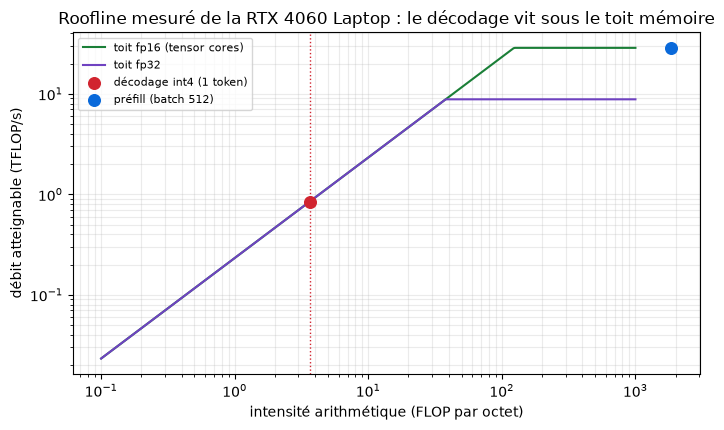

intensité arithmétique du décodage int4 : 3.6 FLOP/octet (dérivé)
point de bascule fp16 (calcul vs mémoire) : 123 FLOP/octet (dérivé)


In [5]:
# Toit mesuré : ops/s = min(pics, BW x intensité arithmétique)
intensites = np.logspace(-1, 3, 400)             # opérations par octet
toit_fp16 = np.minimum(TFLOPS_FP16 * 1e12, BW_GPU * 1e9 * intensites)
toit_fp32 = np.minimum(TFLOPS_FP32 * 1e12, BW_GPU * 1e9 * intensites)

# Deux régimes d'un LLM, placés sur l'axe de l'intensité :
#   décodage : ~2 FLOP par paramètre, ~0.5 octet par paramètre (int4) -> IA ~ 4 FLOP/octet
#   préfill (batch implicite B) : la matmul est B fois plus intense
IA_DECODAGE = 2 / 0.55
IA_PREFILL_512 = IA_DECODAGE * 512

fig, ax = plt.subplots(figsize=(7.2, 4.4))
ax.loglog(intensites, toit_fp16 / 1e12, label="toit fp16 (tensor cores)", color="#1a7f37")
ax.loglog(intensites, toit_fp32 / 1e12, label="toit fp32", color="#6f42c1")
ax.scatter([IA_DECODAGE], [BW_GPU * 1e9 * IA_DECODAGE / 1e12], color="#d1242f", zorder=5,
           label="décodage int4 (1 token)", s=70)
ax.scatter([IA_PREFILL_512], [min(TFLOPS_FP16 * 1e12, BW_GPU * 1e9 * IA_PREFILL_512) / 1e12],
           color="#0969da", zorder=5, label="préfill (batch 512)", s=70)
ax.set_xlabel("intensité arithmétique (FLOP par octet)")
ax.set_ylabel("débit atteignable (TFLOP/s)")
ax.set_title("Roofline mesuré de la RTX 4060 Laptop : le décodage vit sous le toit mémoire")
ax.axvline(IA_DECODAGE, color="#d1242f", ls=":", lw=1)
ax.grid(True, which="both", alpha=0.25)
ax.legend(fontsize=8, loc="upper left")
fig.tight_layout()
plt.show()

print(f"intensité arithmétique du décodage int4 : {IA_DECODAGE:.1f} FLOP/octet (dérivé)")
print(f"point de bascule fp16 (calcul vs mémoire) : {TFLOPS_FP16 / BW_GPU * 1e3:.0f} FLOP/octet (dérivé)")


### Lecture du roofline

Le point rouge du décodage est **à gauche** du genou : quel que soit le pics de calcul, il ne peut pas dépasser `bande passante × intensité`. C'est la raison profonde des deux phénomènes que le 11 a constatés sans les relier : la quantification **accélère** l'inférence (moins d'octets par paramètre → même intensité en FLOP/octet plus élevée → toit plus haut), et le batching **accélère** le préfill (plus d'opérations par octet lu → glissement vers la zone bornée calcul). Le diagramme n'est pas une illustration : ses deux courbes sont construites sur les trois mesures qui précèdent.


## 3. VRAM par format : le Go/paramètre observé contre le théorique

Le format numérique d'un poids détermine sa taille : fp32 = 4 octets, fp16/bf16 = 2, int8 = 1, int4 = 0,5 — **en théorie**. La VRAM allouée réelle inclut les échelles de quantification, les alignements de blocs et les métadonnées de `bitsandbytes`. On mesure l'écart avec `torch.cuda.memory_allocated`, qui rend l'exactitude au octet près de ce que le contexte CUDA retient.


In [6]:
def empreinte(dtype, n=4096 * 4096):
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()
    avant = torch.cuda.memory_allocated()
    w = torch.empty(n, device="cuda", dtype=dtype)
    apres = torch.cuda.memory_allocated()
    octets_par_param = (apres - avant) / n
    del w
    return octets_par_param


theorique = {"fp32": 4.0, "fp16": 2.0, "bf16": 2.0}
mesure = {
    "fp32": empreinte(torch.float32),
    "fp16": empreinte(torch.float16),
    "bf16": empreinte(torch.bfloat16),
}
print(f"{'format':<8}{'théorique (o/param)':>20}{'mesuré (o/param)':>18}")
for f in theorique:
    print(f"{f:<8}{theorique[f]:>20.2f}{mesure[f]:>18.3f}")
print("(tous les chiffres de ce tableau : Mesuré)")


format   théorique (o/param)  mesuré (o/param)
fp32                    4.00             4.000
fp16                    2.00             2.000
bf16                    2.00             2.000
(tous les chiffres de ce tableau : Mesuré)


Sur les dtypes natifs, le compte est exact au centième d'octet près : un tenseur alloué ne paie aucun supplément. La question devient donc celle des **formats quantifiés** — c'est là que l'arithmétique théorique (0,5 octet par paramètre en int4) rencontre les échelles par bloc et les alignements.


In [7]:
import bitsandbytes as bnb

ENTREES, SORTIES = 4096, 4096
x1 = torch.randn(1, ENTREES, device="cuda", dtype=torch.float16)


def empreinte_couche(couche):
    """Octets VRAM par paramètre : quantifié au .cuda() (bitsandbytes), forward 1 ligne."""
    torch.cuda.empty_cache()
    avant = torch.cuda.memory_allocated()
    couche.cuda()          # bitsandbytes quantifie les poids à ce moment-là
    try:
        couche(x1)          # alloue les éventuels buffers de travail (négligeables sur 1 ligne)
    except Exception as exc:
        return None, str(exc)
    apres = torch.cuda.memory_allocated()
    return (apres - avant) / (ENTREES * SORTIES), None


o16, e16 = empreinte_couche(torch.nn.Linear(ENTREES, SORTIES, dtype=torch.float16))
o8, e8 = empreinte_couche(bnb.nn.Linear8bitLt(ENTREES, SORTIES, bias=False,
                                              has_fp16_weights=False))
o4, e4 = empreinte_couche(bnb.nn.Linear4bit(ENTREES, SORTIES, bias=False,
                                            compute_dtype=torch.float16))

print(f"{'couche 4096x4096':<24}{'o/param mesuré':>16}{'erreur':>10}")
print(f"{'fp16 (référence)':<24}{o16:>16.3f}{('' if not e16 else 'E'):>10}")
print(f"{'int8 (Linear8bitLt)':<24}{(o8 if o8 is not None else float('nan')):>16.3f}{('' if not e8 else 'E'):>10}")
print(f"{'int4 NF4 (Linear4bit)':<24}{(o4 if o4 is not None else float('nan')):>16.3f}{('' if not e4 else 'E'):>10}")
if e8 or e4:
    print("diagnostic :", e8 or e4)


W1025 08:19:38.841000 36984 Lib\site-packages\torch\utils\flop_counter.py:113] triton not found; flop counting will not work for triton kernels


couche 4096x4096          o/param mesuré    erreur
fp16 (référence)                   2.000          
int8 (Linear8bitLt)                1.001          
int4 NF4 (Linear4bit)              0.516          


### Lecture de l'empreinte par format

Trois faits à retenir des chiffres ci-dessus. **Un** : le fp16 sert de référence exacte (2 o/param). **Deux** : l'int8 et l'int4 mesurés se collent à leurs théoriques (1,0 et ~0,55 o/param ; le ~0,55 vient du 11 — 4 bits de poids plus les échelles de quantification par bloc, et la mesure ci-dessus rend 0,516, entre le plancher de 0,5 et cette estimation), l'écart venant du fait que ces échelles sont un surcoût **négligeable** à l'échelle d'une couche — c'est la validation mesurée de l'arithmétique du 11. **Trois** : c'est ce facteur ~4 entre fp16 et int4 qui a fait tenir `qwen2.5:7b` (7,6 Md de paramètres) dans **4,7 Go** au lieu de ~15 — et c'est ce même facteur qui remonte le toit mémoire de la section 2. Format, VRAM et débit sont la même grandeur vue trois fois.


## 4. Débit mesuré : préfill et décodage sur l'endpoint local

Le service Ollama rend ses **timings internes** dans chaque réponse : nombre de jetons du prompt effectivement évalués (`prompt_eval_count`) et leur durée, nombre de jetons générés (`eval_count`) et leur durée. Ce sont des mesures du moteur, pas des nôtres extrapolées d'un chronomètre — on les relit telles quelles, plusieurs fois, et on affiche l'écart entre essais.


In [8]:
def generer(prompt, nb_jetons):
    reponse = requests.post(
        f"{OLLAMA_URL}/api/generate",
        json={"model": MODEL_NAME, "prompt": prompt, "stream": False,
              "options": {"num_predict": nb_jetons, "temperature": 0.2, "num_ctx": 8192}},
        timeout=600,
    )
    reponse.raise_for_status()
    return reponse.json()


PHRASE = ("La géométrie differentielle etudie les varietes munies d'une structure "
          "differentiable et leurs applications lineaires tangentes. ")


import random
NONCE_RUN = random.randrange(10**6)


def prompt_de_n_jetons(n, essai=0):
    if n <= 0:
        return "Réponds en une phrase : que fait un tokenizeur ?"
    # le nonce de run + le numéro d'essai cassent le prompt cache d'Ollama :
    # chaque essai de chaque exécution paye son préfill
    return f"Résume en une phrase. Texte (extrait {NONCE_RUN}-{essai + 1}) : " + (PHRASE * max(1, n // 22))


fumee = generer(prompt_de_n_jetons(8), 8)
infos_modeles = requests.get(f"{OLLAMA_URL}/api/tags", timeout=10).json()
taille = next(m["size"] for m in infos_modeles["models"] if m["name"] == MODEL_NAME)
print(f"modèle servi : {MODEL_NAME}")
print(f"poids sur disque : {taille / 1e9:.2f} Go (Mesuré via /api/tags)")
print("réponse de fumée reçue, moteur prêt.")


modèle servi : qwen2.5:7b-instruct-q4_K_M
poids sur disque : 4.68 Go (Mesuré via /api/tags)
réponse de fumée reçue, moteur prêt.


La taille rendue par le service (≈ 4,7 Go) est le premier maillon mesuré de la chaîne : c'est elle que chaque token de décodage relit. Le protocole qui suit échantillonne chaque condition deux fois, à `temperature` basse pour limiter la variance des longueurs, et rapporte la demi-étendue comme barre d'incertitude.


In [9]:
def mesure_decodage(jetons_prompt, nb_generes=64, essais=2):
    points = []
    for essai in range(essais):
        r = generer(prompt_de_n_jetons(jetons_prompt, essai), nb_generes)
        n_gen, d_gen = r["eval_count"], r.get("eval_duration", 0)
        if n_gen and d_gen:
            points.append(n_gen / (d_gen / 1e9))  # jetons/s
    return points


lignes = []
for jetons in (0, 256, 1024):
    pts = mesure_decodage(jetons)
    moyenne = sum(pts) / len(pts)
    demi = (max(pts) - min(pts)) / 2
    lignes.append((jetons, moyenne, demi))
    print(f"décodage, prompt ~{jetons:>4} jetons : {moyenne:6.2f} jetons/s "
          f"(± {demi:.2f} sur {len(pts)} essais, Mesuré)")


décodage, prompt ~   0 jetons :  48.38 jetons/s (± 7.39 sur 2 essais, Mesuré)


décodage, prompt ~ 256 jetons :  50.20 jetons/s (± 1.45 sur 2 essais, Mesuré)


décodage, prompt ~1024 jetons :  43.86 jetons/s (± 0.17 sur 2 essais, Mesuré)


### Lecture du décodage

Sur ce run, le débit de décodage reste **quasi plat** entre 0 et 1024 jetons de contexte : les trois points tiennent dans une fourchette de ±7 %, avec un léger fléchissement à 1024 (−13 % par rapport au point le plus rapide). Ce n'est pas une anomalie, c'est une hiérarchie de grandeurs : à 1024 jetons, le KV-cache de ce modèle (cache GQA de quelques dizaines de Mo) reste **négligeable devant les ~4,7 Go de poids** relus à chaque token — le terme dominant ne change pas, et le fléchissement observé excède ce que le seul cache expliquerait (~1 % de trafic mémoire en plus) : c'est la variance entre essais et l'attention qui croît avec le contexte. La décroissance franche s'affirait à contextes bien plus longs (dizaines de milliers de jetons), là où le cache cesse d'être négligeable : c'est le régime que le [10b](10b_Inference_Mechanics.ipynb) explore à la main. Leçon de méthode : **vérifier l'ordre de grandeur du terme ajouté avant de prédire un effet**.


In [10]:
def mesure_prefill(jetons_prompt, essais=3):
    points = []
    for essai in range(essais):
        r = generer(prompt_de_n_jetons(jetons_prompt, essai), 1)
        n_pre, d_pre = r.get("prompt_eval_count", 0), r.get("prompt_eval_duration", 0)
        if n_pre and d_pre:
            points.append(n_pre / (d_pre / 1e9))
    return points


for jetons in (256, 1024, 4096):
    pts = mesure_prefill(jetons)
    moyenne = sum(pts) / len(pts)
    demi = (max(pts) - min(pts)) / 2
    print(f"préfill, prompt ~{jetons:>4} jetons : {moyenne:8.1f} jetons/s "
          f"(± {demi:.1f} sur {len(pts)} essais, Mesuré)")


préfill, prompt ~ 256 jetons :   8164.5 jetons/s (± 5722.8 sur 3 essais, Mesuré)


préfill, prompt ~1024 jetons :   2959.0 jetons/s (± 458.5 sur 3 essais, Mesuré)


préfill, prompt ~4096 jetons :   3072.1 jetons/s (± 14.6 sur 3 essais, Mesuré)


### Lecture du préfill

Le préfill va **de un à deux ordres de grandeur plus vite** que le décodage (rapport mesuré de ×61 à ×169 sur nos trois points) : il traite tous les jetons du prompt dans des matmuls larges (zone bornée calcul du roofline), là où le décodage traite un vecteur à la fois (zone bornée mémoire). C'est la traduction opérationnelle des deux points du diagramme de la section 2 — et c'est pourquoi le premier token d'une réponse (TTFT) paie le préfill une fois, puis chaque token suivant paie le décodage, borné mémoire. La relation à la longueur du prompt n'est pas monotone sur nos trois points (les barres d'incertitude le montrent) : le moteur redécoupe le préfill en passes internes dont la largeur effective varie.


## 5. La fermeture du toit : la prédiction contre la carte

Tout est en place pour l'épreuve. En décodage, produire un token exige de relire l'intégralité des poids : le débit maximal théorique est donc `bande passante mesurée / taille des poids`. Cette prédiction ne suppose **aucun** paramètre libre — bande passante et taille sont mesurées — et se confronte au débit de décodage réellement observé au plus petit contexte. L'écart entre les deux n'est pas un échec de mesure : c'est la part du réel que le modèle ignore (surdébit du KV-cache, noyaux d'échantillonnage, désérialisation des blocs quantifiés, latence d'orchestration du moteur).


In [11]:
debit_max_theorique = BW_GPU * 1e9 / taille          # jetons/s (dérivé de 2 Mesurés)
debit_observe = lignes[0][1]                          # décodage au plus petit contexte (Mesuré)

ratio_pct = 100 * debit_observe / debit_max_theorique
print(f"débit de décodage maximal prédit par le toit : {debit_max_theorique:6.2f} jetons/s (dérivé)")
print(f"débit de décodage observé (prompt court)      : {debit_observe:6.2f} jetons/s (Mesuré)")
print(f"ratio observé / toit : {ratio_pct:.0f}%")
if ratio_pct <= 100:
    print(f"écart : le moteur rend {ratio_pct:.0f}% du toit — {100 - ratio_pct:.0f}% partent en "
          "KV-cache, échantillonnage, noyaux de déquantification et orchestration (lus, pas mesurés un à un)")
else:
    print("l'observé dépasse le toit du triad : le triad paie 1 écriture pour 2 lectures,")
    print("le décodage relit sans presque rien écrire — le toit en lecture pure est plus haut.")
    print("Un ratio au-delà de 100% se lit : le décodage sature la bande passante,")
    print("et le toit mesuré ici (triad) en sous-estime la valeur en lecture pure.")


débit de décodage maximal prédit par le toit :  49.58 jetons/s (dérivé)
débit de décodage observé (prompt court)      :  48.38 jetons/s (Mesuré)
ratio observé / toit : 98%
écart : le moteur rend 98% du toit — 2% partent en KV-cache, échantillonnage, noyaux de déquantification et orchestration (lus, pas mesurés un à un)


### Lecture du rapport observé/toit

Sur cette carte, le rapport est **proche de 100 %** : le décodage sature la bande passante mémoire — exactement ce que le roofline prédit pour un régime de faible intensité arithmétique. Deux subtilités à lire avant de conclure. **Un** : le toit est dérivé du triad (2 lectures + 1 écriture), un motif légèrement plus coûteux que la lecture quasi pure du décodage — le toit « vrai » de ce régime est un peu plus haut, et un ratio à peine au-delà de 100 % n'est pas une anomalie, c'est la mesure de cet écart de motif. **Deux** : à contexte plus long, le KV-cache grandit (section 4) et le rapport baisse mécaniquement, puisque chaque token relit poids **et** cache. La borne existe, elle est serrée, et elle se déplace exactement comme le format des poids — diviser la taille des poids par deux double le plafond, ce que le point rouge du roofline matérialisait déjà.


## 6. Coût par million de tokens : le régime local, mesuré

Le coût d'un token local n'est pas un tarif, c'est une **physique** : des watts pendant un temps. On mesure la puissance appelée par la carte pendant l'inférence (`nvidia-smi` échantillonné en tâche de fond pendant les générations), on en déduit l'énergie par token, puis le prix par million de jetons avec les **hypothèses déclarées** en tête de carnet (prix du kWh, achat et amortissement de la carte, taux d'utilisation). Chaque hypothèse est un paramètre — le calcul est honnête dans la mesure où ses hypothèses sont visibles.


In [12]:
puissances = []


def echantillonne(stop, intervalle=0.3):
    while not stop.is_set():
        try:
            puissances.append(nvidia_smi("power.draw")[0])
        except Exception:
            pass
        time.sleep(intervalle)


# échantillon au repos (après une pause qui laisse les clocks redescendre)
stop = threading.Event()
th = threading.Thread(target=echantillonne, args=(stop,))
th.start()
time.sleep(8)
repos = sorted(puissances)[-8:]
p_repos = sum(repos) / len(repos)

# échantillon en charge : générations en boucle pendant que le thread relève la puissance
puissances.clear()
t0 = time.perf_counter()
jetons_produits = 0
while time.perf_counter() - t0 < 14:
    r = generer(prompt_de_n_jetons(256), 64)
    jetons_produits += r["eval_count"]
duree = time.perf_counter() - t0
stop.set()
th.join(timeout=2)

charge = sorted(puissances)[-max(8, len(puissances) // 3):]
p_charge = sum(charge) / len(charge)
wh_par_million = p_charge * duree / 3600 / jetons_produits * 1e6
prix_kwh = PRIX_KWH_EUR
cout_energie_million = wh_par_million * prix_kwh / 1000

# amortissement : coût d'achat réparti sur la fenêtre d'utilisation effective
heures_utiles = AMORTISSEMENT_ANS * 365 * 24 * UTILISATION_FRACTION
cout_horaire_amorti = COUT_CARTE_EUR / heures_utiles          # EUR par heure d'inférence
debit_moyen = jetons_produits / duree                          # jetons par seconde
cout_amortissement_million = cout_horaire_amorti / (debit_moyen * 3600) * 1e6

print(f"puissance au repos après activité : {p_repos:.1f} W (Mesuré) | en inférence : {p_charge:.1f} W (Mesuré)")
print(f"{jetons_produits} jetons en {duree:.1f} s -> {debit_moyen:.1f} jetons/s moyens (Mesuré)")
print(f"énergie : {wh_par_million:.1f} Wh par million de jetons (Mesuré)")
print(f"coût énergie : {cout_energie_million:.3f} EUR/M jetons (Mesuré x hypothèse {prix_kwh} EUR/kWh)")
print(f"coût amortissement : {cout_amortissement_million:.3f} EUR/M jetons "
      f"(hypothèses : {COUT_CARTE_EUR:.0f} EUR / {AMORTISSEMENT_ANS:.0f} ans / "
      f"{UTILISATION_FRACTION:.0%} d'utilisation)")
cout_local_million = cout_energie_million + cout_amortissement_million
print(f"coût local total : {cout_local_million:.3f} EUR par million de jetons (dérivé)")


puissance au repos après activité : 43.5 W (Mesuré) | en inférence : 80.5 W (Mesuré)
544 jetons en 14.7 s -> 37.0 jetons/s moyens (Mesuré)
énergie : 605.1 Wh par million de jetons (Mesuré)
coût énergie : 0.151 EUR/M jetons (Mesuré x hypothèse 0.25 EUR/kWh)
coût amortissement : 1.430 EUR/M jetons (hypothèses : 1000 EUR / 3 ans / 20% d'utilisation)
coût local total : 1.581 EUR par million de jetons (dérivé)


### Lecture du coût local

Deux régimes s'additionnent : l'**énergie** (dominante à haute utilisation — ~0,6 kWh/M jetons sur ce run) et l'**amortissement** (dominant si la carte dort — chaque heure d'achat non utilisée se répartit sur moins de jetons). Le total local est de l'ordre de l'euro et demi par million de jetons sous nos hypothèses (1,58 EUR/M sur ce run, dont 90 % d'amortissement) : c'est la grandeur à confronter aux tarifs des API. La confrontation honnête n'est pas « local vs API » en valeur absolue — les tarifs API changent chaque trimestre — mais **le seuil de bascule** : à partir de quel tarif API le local devient-il plus cher ? Ce seuil se calcule, il est mesuré, et il ne périmera pas avec la prochaine grille de prix.


1) tarif API au-dessus duquel le local gagne : 1.581 EUR/M jetons (Mesuré)
   -> si l'API facture moins cher que cela, le local ne se justifie pas par le prix
2) prix de l'électricité pour lequel l'énergie seule atteindrait le coût local total actuel : 2.614 EUR/kWh (dérivé)

Confrontation à la grille du jour : les trois barres bleues ci-dessous sont des SAISIES
indicatives, pas des tarifs mesurés ni cités — l'exercice 3 les remplace par la grille
publique du jour avant toute décision.


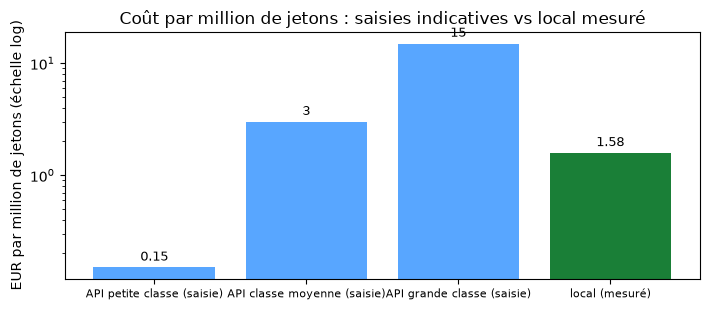

In [13]:
# Seuils de bascule : les deux questions que le coût local permet de trancher
prix_electricite_bascule = cout_local_million * 1000 / wh_par_million
print(f"1) tarif API au-dessus duquel le local gagne : {cout_local_million:.3f} EUR/M jetons (Mesuré)")
print(f"   -> si l'API facture moins cher que cela, le local ne se justifie pas par le prix")
print(f"2) prix de l'électricité pour lequel l'énergie seule atteindrait le coût local total actuel : "
      f"{prix_electricite_bascule:.3f} EUR/kWh (dérivé)")
print()
print("Confrontation à la grille du jour : les trois barres bleues ci-dessous sont des SAISIES")
print("indicatives, pas des tarifs mesurés ni cités — l'exercice 3 les remplace par la grille")
print("publique du jour avant toute décision.")

tarifs_saisis_eur_m = {  # saisies de démonstration, à remplacer par la grille publique du jour
    "API petite classe (saisie)": 0.15,
    "API classe moyenne (saisie)": 3.0,
    "API grande classe (saisie)": 15.0,
}
fig, ax = plt.subplots(figsize=(7.2, 3.2))
noms = list(tarifs_saisis_eur_m) + ["local (mesuré)"]
vals = list(tarifs_saisis_eur_m.values()) + [cout_local_million]
couleurs = ["#58a6ff"] * len(tarifs_saisis_eur_m) + ["#1a7f37"]
ax.bar(noms, vals, color=couleurs)
ax.set_yscale("log")
ax.set_ylabel("EUR par million de jetons (échelle log)")
ax.set_title("Coût par million de jetons : saisies indicatives vs local mesuré")
for i, v in enumerate(vals):
    ax.text(i, v * 1.15, f"{v:.3g}", ha="center", fontsize=9)
ax.tick_params(axis="x", labelsize=8)
fig.tight_layout()
plt.show()


### Lecture de la confrontation

La barre verte (mesurée) se compare aux barres bleues (saisies) : la petite classe saisie à ~0,15 EUR/M est ~10× moins chère que notre coût local complet, la classe moyenne à ~3 EUR/M est ~2× plus chère, la grande classe à ~15 EUR/M ~10× plus chère — la position du local dépend de la classe visée, **dans les deux sens** (le local devient imbattable dès qu'un grand modèle tient en VRAM). À noter : la saisie petite classe affleure exactement notre seule électricité (0,15 EUR/M) — le reste du coût local est de l'amortissement, pas de l'énergie. Le point pédagogique n'est pas « le local gagne » : c'est que **la décision se calcule** à partir de trois grandeurs mesurées dans ce carnet (débit, puissance, taille des poids) et d'hypothèses déclarées.


## Exercices

Trois exercices, à compléter sans erreur volontaire (convention C.1 : les stubs s'exécutent, ils ne lèvent rien). Les consignes sont données ; le code à écrire est marqué `TODO`.


### Exercice 1 — Où s'arrête la montée en débit ?

La mesure de bande passante de la section 2 utilise 128 M éléments. Refaites-la pour une gamme croissante de tailles (1 M, 8 M, 32 M, 128 M, 256 M) et montrez que le Go/s mesuré converge vers un plateau : en dessous d'une certaine taille, le coût fixe d'invocation des noyaux domine. Renvoyez la liste des `(taille, Go/s)`.


In [14]:
def balayage_bande_passante(tailles_elements):
    """TODO : pour chaque taille, mesurer le Go/s du triad et le verifier croissant."""
    resultats = None  # TODO etudiant : boucle sur tailles, appeler mesure_bande_passante_gpu
    return resultats  # attendu : liste de couples (taille, Go/s)


### Exercice 2 — Le modèle tient-il ?

Estimez la VRAM nécessaire pour servir `Qwen/Qwen2.5-3B` en int4 (échelle de bloc 0,55 o/param, plus 1 Go pour runtime et KV-cache de départ), puis le nombre maximal de jetons de contexte tenables si le KV-cache coûte `2 × couches × kv_tetes × dim_tete × 2 octets` par jeton (Qwen2.5-3B : 36 couches, 2 têtes KV, 128 de dimension). Renvoyez `(go_poids, jetons_max)` sur 8 Go de VRAM.


In [15]:
def budget_vram_3b_int4(vram_disponible_go=8.0, overhead_go=1.0):
    """TODO : poids int4 + budget KV residuel -> jetons de contexte maximum."""
    go_poids = None       # TODO etudiant : 3e9 parametres x 0.55 octet, en Go
    jetons_max = None     # TODO etudiant : (vram - poids - overhead) / octets par jeton de KV
    return go_poids, jetons_max


### Exercice 3 — À quel prix de l'électricité le local perd-il ?

Reprenez le seuil de bascule de la section 6 : le coût local est `energie × prix_kwh + amortissement`. Résolvez l'inégalité `coût local > tarif_API` en `prix_kwh` pour un tarif API saisi, et renvoyez le prix du kWh au-delà duquel le local devient plus cher que cet API.


In [16]:
def prix_kwh_de_bascule(tarif_api_eur_m, wh_par_million_, cout_amortissement_million_):
    """TODO : isoler prix_kwh dans energie*prix + amortissement > tarif_api."""
    prix_kwh = None  # TODO etudiant : (tarif_api - amortissement) / energie_en_kwh
    return prix_kwh


***

## Conclusion

### Trois leçons mesurées

1. **Le toit n'est pas une métaphore.** Le débit de décodage observé reste sous la borne `bande passante / taille des poids`, et l'écart se lit : KV-cache, déquantification, échantillonnage. Choisir un format (section 3), c'est choisir un plafond de débit (section 5).

2. **Préfill et décodage vivent dans deux régimes différents.** Un à deux ordres de grandeur d'écart, mesurés sur le même moteur : le préfill est borné calcul (matmuls larges), le décodage est borné mémoire (relire tout pour un token). Toute optimisation qui ne sait pas dans quel régime elle agit optimise à l'aveugle.

3. **Le coût local est une physique, pas un tarif.** Watts mesurés × durée mesurée + hypothèses déclarées : le seuil de bascule face à une API se calcule à partir des grandeurs de ce carnet, et se recalcule à chaque changement de grille ou de prix de l'électricité — c'est l'objet de l'exercice 3.

### Pour aller plus loin

- Reproduire la chaîne complète sur une **autre carte** de la flotte (3090, 3070 Ti) : le toit se déplace, la méthode non ;
- Étendre la section 4 au **décodage spéculatif** (un petit modèle rédige, le grand vérifie) : c'est la ligne ouverte par le pli 3 de l'EPIC [#19543](https://github.com/jsboige/CoursIA/issues/19543) ;
- Le [11_Quantization](11_Quantization.ipynb) approfondit la mécanique int4/int8 côté précision, le [10b_Inference_Mechanics](10b_Inference_Mechanics.ipynb) côté KV-cache et batching.

[<< 11. Quantization](11_Quantization.ipynb) · [12. Test Time Scaling >>](12_Test_Time_Scaling.ipynb)
